## 1_5_3_2LP_with_Linear_AF in hidden layers
 to understand the impact of linear AF in hidden layers -> will make the whole network to collapse into a single layered network

### to perform Binary Classification


In [11]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [12]:
h = 1e-4   # small value for numerical differentiation

# (i) Define Numerical Differentiation (CDA) and GD methods

In [13]:
def numerical_differentiation(x, y, f_loss, f_predict, parameters):
    p = parameters
    p_gradients = []
    for i in range(len(p)):
        # ex) p[0]= wh, p[1]= bh,
        #     p[2]= wo, p[3]= bo
        rows, cols = p[i].shape
        grad = np.zeros_like(p[i])
        
        # Apply numerical differentiation to all elements in p[i].
        for row in range(rows):
            for col in range(cols):
                # Measures the change in loss when the p[i][row, col]
                # element changes by h. The remaining elements are
                # fixed. This is an approximate gradient.
                p_org = p[i][row, col]    # original value of p
                p[i][row, col] = p_org + h # The element at position
                                           # (row, col) increases by h.
                y_hat = f_predict(x)       # calculate y_hat
                f1 = f_loss(y, y_hat)      # The amount of change in loss
                
                p[i][row, col] = p_org - h # decreases by h.
                y_hat = f_predict(x)       # calculate y_hat
                f2 = f_loss(y, y_hat)      # The amount of
                                           # change in loss.
                p[i][row, col] = p_org     # Restore p back to
                                           # its original value.
                                           
                # the gradient at position (row, col)
                grad[row, col] = (f1 - f2) / (2. * h)
        p_gradients.append(grad) # gradients for all parameters
    return p_gradients

In [14]:
# Perform Gradient Descent
def gradient_descent(x, y, alpha, f_loss,
                     f_predict, parameters):
    p = parameters
    grad = numerical_differentiation(x, y,
                                     f_loss,
                                     f_predict,
                                     parameters)
                                     
    for i in range(len(p)):
        p[i] = p[i] - alpha * grad[i]

## 1_2 Two Layered Perceptron - Binary Classification

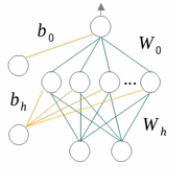

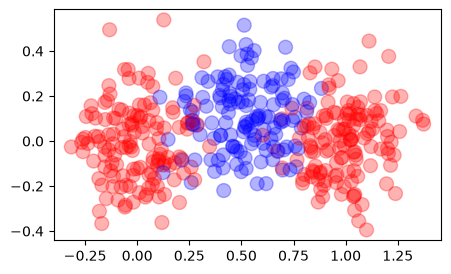

In [15]:
# Generate a dataset
x, y = make_blobs(n_samples=400, n_features=2,
                  centers=[[0., 0.], [0.5, 0.1], [1., 0.]],
                  cluster_std=0.15, center_box=(-1., 1.))

y[y == 2] = 0 # y = [0, 1, 2] -> [0, 1]
y = y.reshape(-1, 1)

# See the data visually.
plt.figure(figsize=(5,3))
color = [['red', 'blue'][a] for a in y.reshape(-1,)]
plt.scatter(x[:, 0], x[:, 1], s=100, c=color, alpha=0.3)
plt.show()

### Observation:

From above diagram we note that this is a binary classification problem, but a single line (SLP) cannot separate those classes so we need MLP to create a non-linear decision boundary to separate our data well.

In [16]:
# Generate the training and test data
x_train, x_test, y_train, y_test = train_test_split(x, y)

# Create an two-layered ANN model.
n_input = x.shape[1]  # the number of input neurons
n_output = 1          # the number of output neurons
n_hidden = 16         # the number of hidden neurons
alpha = 0.05          # learning rate

# initialize the parameters randomly.
wh = np.random.normal(size=(n_input, n_hidden))  # weights of hidden layer (2x16)
bh = np.zeros(shape=(1, n_hidden))               # biases of hidden layer (1x16)
wo = np.random.normal(size=(n_hidden, n_output)) # weights of output layer (16x1)
bo = np.zeros(shape=(1, n_output))               # bias of output layer(1x1)
parameters = [wh, bh, wo, bo]                    # parameter list

# # activation functions
def sigmoid(x): return 1. / (1. + np.exp(-x))
# def relu(x):    return np.maximum(0, x)

# loss function: binary cross entropy
def loss(y, y_hat):
    return -np.mean(y * np.log(y_hat) + (1. - y) * np.log(1. - y_hat))

## !! 
- we are changing the hidden layer non-liner ReLU AF from previous experiment into linear AF - fh(z)=z

- h_out being the output of hidden layer. instead of applying a ReLU to it, we passing z as is.

- z = np.dot(x, p[0]) + p[1] 

- output sigmoid function is kept - it doesnt need to change to understand the collapse

0: train_loss=1.5212, val_loss=1.5904
10: train_loss=0.5977, val_loss=0.5907
20: train_loss=0.6001, val_loss=0.6092
30: train_loss=0.5922, val_loss=0.5895
40: train_loss=0.5847, val_loss=0.5877
50: train_loss=0.5872, val_loss=0.5902
60: train_loss=0.5840, val_loss=0.5903
70: train_loss=0.5936, val_loss=0.6074
80: train_loss=0.6017, val_loss=0.6173
90: train_loss=0.5871, val_loss=0.5988
100: train_loss=0.5854, val_loss=0.5955
110: train_loss=0.5868, val_loss=0.5979
120: train_loss=0.5910, val_loss=0.5929
130: train_loss=0.5857, val_loss=0.5964
140: train_loss=0.5883, val_loss=0.5994
150: train_loss=0.5929, val_loss=0.6075
160: train_loss=0.6107, val_loss=0.6069
170: train_loss=0.5833, val_loss=0.5925
180: train_loss=0.5878, val_loss=0.5997
190: train_loss=0.5832, val_loss=0.5897


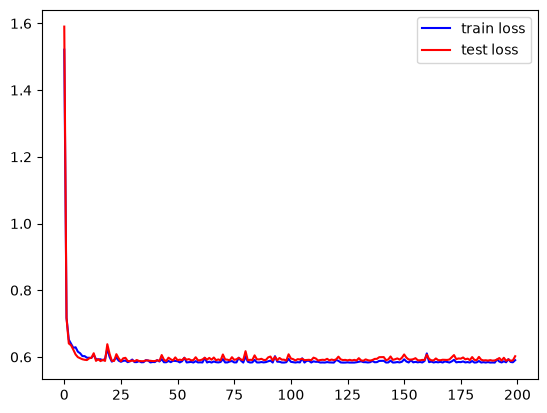

Accuracy of training data = 0.7200
Accuracy of test data = 0.7000


In [ ]:
# Output from the ANN model: prediction process
def predict(x, proba=True):
    p = parameters
    h_out = np.dot(x, p[0]) + p[1]        # <================================
    o_out = sigmoid(np.dot(h_out, p[2]) + p[3]) # output from output layer
    
    if proba:
        return o_out                            # return probability
    else:
        return (o_out > 0.5) * 1                # return class

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = [] # loss history of training data
    hv_loss = [] # loss history of test data
    for epoch in range(epochs):
        # measure the losses during training
        # loss for training data
        ht_loss.append(loss(y, predict(x)))
        
        # loss for validation data
        hv_loss.append(loss(y_val, predict(x_val)))
        
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss, predict,
                             parameters)
            
        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
            
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_test, y_test,
                             epochs=200, batch_size=50)

# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='test loss')
plt.legend()
plt.show()

# Check the accuracy.
y_pred = predict(x_train, proba=False)
acc = (y_pred == y_train).mean()
print("Accuracy of training data = {:.4f}".format(acc))

y_pred = predict(x_test, proba=False)
acc = (y_pred == y_test).mean()
print("Accuracy of test data = {:.4f}".format(acc))

## Observation

We can observe that when we use two layer perceptron with linear activation function, even though the loss decreases as the epoch progresses, it is still higher than the previous method. It can also be seen that the accuracy has reduced significantly.

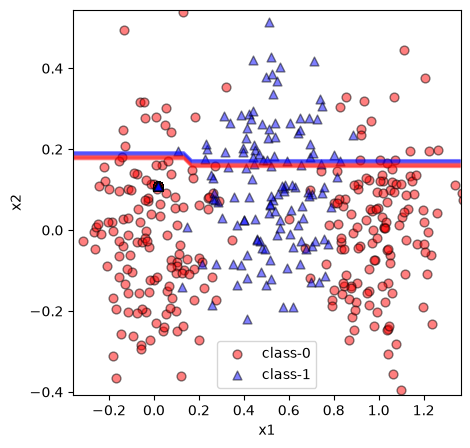

In [18]:
# Visualize the linear decision boundary
# reference : https://psrivasin.medium.com/
# plotting-decision-boundaries-using-numpy-and-matplotlib-
# f5613d8acd19
x_min, x_max = x_test[:, 0].min() - 0.1, x_test[:,0].max() + 0.1
y_min, y_max = x_test[:, 1].min() - 0.1, x_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 50),
                     np.linspace(y_min, y_max, 50))
x_in = np.c_[xx.ravel(), yy.ravel()]

# Predict the classes of the data points in the x_in variable.
y_pred = predict(x_in, proba=False).astype('int8')
y_pred = y_pred.reshape(xx.shape)

plt.figure(figsize=(5, 5))
m = ['o', '^']
color = ['red', 'blue']
for i in [0, 1]:
    idx = np.where(y == i)
    plt.scatter(x[idx, 0], x[idx, 1],
                c = color[i],
                marker = m[i],
                s = 40,
                edgecolor = 'black',
                alpha = 0.5,
                label='class-' + str(i))

plt.contour(xx, yy, y_pred, cmap=ListedColormap(color), alpha=0.5)
plt.axis('tight')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()

## Observation

From this diagram, we can see a linear decision boundary, trying to classify the Data points. This shows the collapse of two layer perceptron network has collapsed to a linear function function. It is not able to provide a good decision boundary to perform binary classification on these data points.